In [ ]:
import numpy as np
import os
import pandas as pd


# ============================================================
# SETTINGS
# ============================================================

objectives = ["Single", "Multi"]

methods = [
    "USGS",
    "Furey",
    "Eckhardt",
    "LocalHYSEP"
]

START_YEAR = 2000
END_YEAR = 2013

YEARS = np.arange(
    START_YEAR,
    END_YEAR + 1
)

test = "PUB"

models = [
    "HBV",
    "HBV_capillary",
    # "marrmot_PRMS"
]


# ============================================================
# DATES
# ============================================================

dates = pd.date_range(
    "1981-01-01",
    "2014-12-31",
    freq="D"
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Basin_wise_csv"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# TIFF BASIN RECHARGE
# ============================================================

TIFF_CSV = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/gauge_basin_average/"
    "RC_eff_basin_mean_2000_2013_wide.csv"
)

tiff_data = pd.read_csv(
    TIFF_CSV
)


# ============================================================
# FIND GAGEID COLUMN
# ============================================================

if "GAGEID" in tiff_data.columns:

    ID_COL = "GAGEID"

elif "STAID" in tiff_data.columns:

    ID_COL = "STAID"

elif "ID" in tiff_data.columns:

    ID_COL = "ID"

else:

    raise ValueError(
        "No GAGEID/STAID/ID column found."
    )


# ============================================================
# FORCE GAGEIDS TO INTEGER
# ============================================================

tiff_data["GAGEID_INT"] = pd.to_numeric(
    tiff_data[ID_COL],
    errors="coerce"
)

tiff_data = tiff_data[
    tiff_data["GAGEID_INT"].notna()
].copy()

tiff_data["GAGEID_INT"] = (
    tiff_data["GAGEID_INT"]
    .astype(np.int64)
)


# ============================================================
# CHECK DUPLICATE GAGEIDS
# ============================================================

if tiff_data["GAGEID_INT"].duplicated().any():

    duplicate_ids = (
        tiff_data.loc[
            tiff_data["GAGEID_INT"].duplicated(
                keep=False
            ),
            "GAGEID_INT"
        ]
        .unique()
    )

    raise ValueError(
        f"Duplicate GAGEIDs in TIFF CSV: "
        f"{duplicate_ids}"
    )


# ============================================================
# CREATE TIFF LOOKUP
# ============================================================

# GAGEID -> [2000, 2001, ..., 2013]

tiff_lookup = {}

for _, row in tiff_data.iterrows():

    gauge = int(
        row["GAGEID_INT"]
    )

    tiff_lookup[gauge] = np.array(
        [
            row[f"mean_{year}"]
            for year in YEARS
        ],
        dtype=float
    )


print(
    f"TIFF basins: {len(tiff_lookup)}"
)


# ============================================================
# FUNCTION: GET DYNAMIC PARAMETERS
# ============================================================

def get_dyn(model):

    if model == "HBV":

        return (
            "parBETA_parBETAET_"
        )

    elif model == "HBV_capillary":

        return (
            "parBETA_parBETAET_"
            "parK0_parUZL_"
        )

    elif model == "marrmot_PRMS":

        return (
            "alpha_cgw_scx_tt_"
        )

    else:

        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# FUNCTION: CALCULATE ANNUAL MEANS
# ============================================================

def annual_means(recharge):

    recharge = np.asarray(
        recharge,
        dtype=float
    )


    # --------------------------------------------------------
    # Expected input:
    #
    # Either:
    #     (time, basins)
    #
    # or:
    #     (basins, time)
    # --------------------------------------------------------

    if recharge.ndim != 2:

        raise ValueError(
            f"Expected 2D recharge array, "
            f"got shape {recharge.shape}"
        )


    # --------------------------------------------------------
    # If input is:
    #
    # (time, basins)
    #
    # transpose it to:
    #
    # (basins, time)
    # --------------------------------------------------------

    if recharge.shape[0] == len(dates):

        recharge = recharge.T


    # --------------------------------------------------------
    # Otherwise make sure second dimension is time
    # --------------------------------------------------------

    elif recharge.shape[1] != len(dates):

        raise ValueError(
            f"Unexpected recharge shape: "
            f"{recharge.shape}. "
            f"Expected one dimension to equal "
            f"{len(dates)}."
        )


    # --------------------------------------------------------
    # Create output array
    #
    # rows    = basins
    # columns = years
    # --------------------------------------------------------

    annual = np.full(
        (
            recharge.shape[0],
            len(YEARS)
        ),
        np.nan
    )


    # --------------------------------------------------------
    # Calculate annual means
    # --------------------------------------------------------

    for j, year in enumerate(YEARS):

        mask = (
            dates.year == year
        )

        annual[:, j] = np.nanmean(
            recharge[:, mask],
            axis=1
        )


    return annual


# ============================================================
# FUNCTION: LOAD RECHARGE / PERCOLATION DATA
# ============================================================

def load_recharge(
    model,
    folder,
    run_name,
    dyn
):

    base_path = os.path.join(
        folder,
        run_name,
        dyn,
        "ts1980_2014"
    )


    # ========================================================
    # HBV
    #
    # Recharge = percolation
    # ========================================================

    if model == "HBV":

        percolation_path = os.path.join(
            base_path,
            "percolation.npy"
        )

        if not os.path.exists(
            percolation_path
        ):

            print(
                "Missing percolation.npy:"
            )

            print(
                percolation_path
            )

            return None


        print(
            "Loading percolation.npy"
        )

        percolation = np.squeeze(
            np.load(
                percolation_path
            )
        )

        return percolation


    # ========================================================
    # HBV_capillary
    #
    # Recharge =
    #
    # percolation - capillary
    # ========================================================

    elif model == "HBV_capillary":

        percolation_path = os.path.join(
            base_path,
            "percolation.npy"
        )

        capillary_path = os.path.join(
            base_path,
            "capillary.npy"
        )


        if not os.path.exists(
            percolation_path
        ):

            print(
                "Missing percolation.npy:"
            )

            print(
                percolation_path
            )

            return None


        if not os.path.exists(
            capillary_path
        ):

            print(
                "Missing capillary.npy:"
            )

            print(
                capillary_path
            )

            return None


        print(
            "Loading percolation.npy"
        )

        percolation = np.squeeze(
            np.load(
                percolation_path
            )
        )


        print(
            "Loading capillary.npy"
        )

        capillary = np.squeeze(
            np.load(
                capillary_path
            )
        )


        # ----------------------------------------------------
        # Check shapes
        # ----------------------------------------------------

        if percolation.shape != capillary.shape:

            raise ValueError(
                "percolation and capillary "
                "have different shapes: "
                f"{percolation.shape} vs "
                f"{capillary.shape}"
            )


        # ----------------------------------------------------
        # Calculate recharge
        # ----------------------------------------------------

        recharge = (
            percolation
            -
            capillary
        )


        return recharge


    # ========================================================
    # marrmot_PRMS
    #
    # Recharge =
    #
    # flux_gad + flux_sep
    # ========================================================

    elif model == "marrmot_PRMS":

        flux_gad_path = os.path.join(
            base_path,
            "flux_gad.npy"
        )

        flux_sep_path = os.path.join(
            base_path,
            "flux_sep.npy"
        )


        if not os.path.exists(
            flux_gad_path
        ):

            print(
                "Missing flux_gad.npy:"
            )

            print(
                flux_gad_path
            )

            return None


        if not os.path.exists(
            flux_sep_path
        ):

            print(
                "Missing flux_sep.npy:"
            )

            print(
                flux_sep_path
            )

            return None


        print(
            "Loading flux_gad.npy"
        )

        flux_gad = np.squeeze(
            np.load(
                flux_gad_path
            )
        )


        print(
            "Loading flux_sep.npy"
        )

        flux_sep = np.squeeze(
            np.load(
                flux_sep_path
            )
        )


        # ----------------------------------------------------
        # Check shapes
        # ----------------------------------------------------

        if flux_gad.shape != flux_sep.shape:

            raise ValueError(
                "flux_gad and flux_sep "
                "have different shapes: "
                f"{flux_gad.shape} vs "
                f"{flux_sep.shape}"
            )


        # ----------------------------------------------------
        # Calculate recharge
        # ----------------------------------------------------

        recharge = (
            flux_gad
            +
            flux_sep
        )


        return recharge


    else:

        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# NUMBER OF REGIONS
# ============================================================

if test == "PUB":

    n_regions = 11

else:

    n_regions = 8


# ============================================================
# LOOP METHODS
# ============================================================

for method in methods:


    # ========================================================
    # LOOP MODELS
    # ========================================================

    for model in models:


        print("\n")
        print("=" * 80)

        print(
            f"METHOD = {method}"
        )

        print(
            f"MODEL  = {model}"
        )

        print(
            f"TEST   = {test}"
        )

        print("=" * 80)


        # ====================================================
        # GET DYNAMIC PARAMETER NAME
        # ====================================================

        dyn = get_dyn(
            model
        )


        # ====================================================
        # HOLD ALL GAGES FROM ALL REGIONS
        # ====================================================

        all_annual_results = []


        # ====================================================
        # LOOP REGIONS
        # ====================================================

        for region in range(
            1,
            n_regions + 1
        ):


            print(
                f"\nRegion {region}"
            )


            # =================================================
            # PATHS
            # =================================================

            if test == "PUB":

                folder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUB/"
                    f"{method}_{objectives[1]}/"
                    f"{region}/"
                )

                sfolder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUB/"
                    f"OUTPUTS_PUB_{objectives[0]}/"
                    f"{region}/"
                )

                forcing_path = (
                    f"/scratch/data/"
                    f"PUB_DATA/test/{region}/"
                    f"daymet_19800101_20141231_"
                    f"forcing_671_baseflow_mmday.npy"
                )


            else:

                folder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUR/"
                    f"{method}_{objectives[1]}/"
                    f"Region_{region}/"
                )

                sfolder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUR/"
                    f"OUTPUTS_PUR_{objectives[0]}/"
                    f"Region_{region}/"
                )

                forcing_path = (
                    f"/scratch/data/"
                    f"PUR_DATA/test/Region_{region}/"
                    f"daymet_19800101_20141231_"
                    f"forcing_671_baseflow_mmday.npy"
                )


            # =================================================
            # RUN NAME
            # =================================================

            run_name = (
                f"LSTM_{model}_"
                f"E50_R365_B100_H256_"
                f"tr1989_1999_n16_111111"
            )


            # =================================================
            # CHECK FORCING
            # =================================================

            if not os.path.exists(
                forcing_path
            ):

                print(
                    "Missing forcing file -- skipping region"
                )

                print(
                    forcing_path
                )

                continue


            # =================================================
            # LOAD FORCING
            # =================================================

            print(
                "Loading forcing..."
            )

            forcing = np.load(
                forcing_path
            )


            # =================================================
            # LOAD OLD RECHARGE
            #
            # Uses Single objective directory
            # =================================================

            print(
                "\nLoading OLD recharge..."
            )

            old_recharge = load_recharge(
                model=model,
                folder=sfolder,
                run_name=run_name,
                dyn=dyn
            )


            if old_recharge is None:

                print(
                    "Could not load OLD recharge "
                    "-- skipping region"
                )

                continue


            # =================================================
            # LOAD NEW RECHARGE
            #
            # Uses Multi objective directory
            # =================================================

            print(
                "\nLoading NEW recharge..."
            )

            new_recharge = load_recharge(
                model=model,
                folder=folder,
                run_name=run_name,
                dyn=dyn
            )


            if new_recharge is None:

                print(
                    "Could not load NEW recharge "
                    "-- skipping region"
                )

                continue


            # =================================================
            # CHECK OLD / NEW SHAPES
            # =================================================

            if old_recharge.shape != new_recharge.shape:

                raise ValueError(
                    "OLD and NEW recharge arrays "
                    "have different shapes: "
                    f"{old_recharge.shape} vs "
                    f"{new_recharge.shape}"
                )


            # =================================================
            # CALCULATE ANNUAL MEANS
            #
            # This happens AFTER constructing recharge:
            #
            # HBV:
            #     percolation
            #
            # HBV_capillary:
            #     percolation - capillary
            #
            # marrmot:
            #     flux_gad + flux_sep
            # =================================================

            print(
                "\nCalculating annual means..."
            )

            annual_old = annual_means(
                old_recharge
            )

            annual_new = annual_means(
                new_recharge
            )


            # =================================================
            # NUMBER OF BASINS
            # =================================================

            n_basins = (
                annual_old.shape[0]
            )

            print(
                f"Basins: {n_basins}"
            )


            # =================================================
            # LOOP BASINS
            # =================================================

            for basin in range(
                n_basins
            ):


                # =================================================
                # GET GAGEID
                #
                # GAGEID = forcing[basin, 0, 14]
                # =================================================

                gauge_raw = forcing[
                    basin,
                    0,
                    14
                ]


                # =================================================
                # CHECK GAGEID
                # =================================================

                if not np.isfinite(
                    gauge_raw
                ):

                    continue


                gauge = int(
                    gauge_raw
                )


                # =================================================
                # CHECK TIFF MATCH
                # =================================================

                if gauge not in tiff_lookup:

                    print(
                        f"  GAGEID {gauge} "
                        f"not found in TIFF CSV"
                    )

                    continue


                # =================================================
                # GET TIFF ANNUAL VALUES
                # =================================================

                tiff_series = tiff_lookup[
                    gauge
                ]


                # =================================================
                # GET SIMULATION ANNUAL VALUES
                # =================================================

                old_series = annual_old[
                    basin
                ]

                new_series = annual_new[
                    basin
                ]


                # =================================================
                # ADD ONE ROW FOR EACH YEAR
                # =================================================

                for j, year in enumerate(
                    YEARS
                ):

                    all_annual_results.append(
                        {
                            "year": int(year),

                            "gageid": int(gauge),

                            "tiff": tiff_series[j],

                            "sim_old": old_series[j],

                            "sim_new": new_series[j]
                        }
                    )


                print(
                    f"  GAGEID {gauge}: "
                    f"2000-2013 added"
                )


        # ========================================================
        # SAVE CSV FOR THIS METHOD + MODEL
        # ========================================================

        if len(
            all_annual_results
        ) > 0:


            annual_df = pd.DataFrame(
                all_annual_results,
                columns=[
                    "year",
                    "gageid",
                    "tiff",
                    "sim_old",
                    "sim_new"
                ]
            )


            # ====================================================
            # SORT
            # ====================================================

            annual_df = annual_df.sort_values(
                by=[
                    "gageid",
                    "year"
                ]
            ).reset_index(
                drop=True
            )


            # ====================================================
            # OUTPUT FILE
            # ====================================================

            output_csv = os.path.join(
                OUTPUT_DIR,
                (
                    f"annual_recharge_"
                    f"{test}_"
                    f"{method}_"
                    f"{model}_"
                    f"{START_YEAR}_"
                    f"{END_YEAR}.csv"
                )
            )


            # ====================================================
            # SAVE
            # ====================================================

            annual_df.to_csv(
                output_csv,
                index=False
            )


            # ====================================================
            # PRINT SUMMARY
            # ====================================================

            print("\n")
            print("-" * 80)

            print(
                "CSV SAVED:"
            )

            print(
                output_csv
            )

            print(
                f"Rows: {len(annual_df)}"
            )

            print(
                f"GAGEIDs: "
                f"{annual_df['gageid'].nunique()}"
            )

            print(
                f"Years: "
                f"{annual_df['year'].min()} - "
                f"{annual_df['year'].max()}"
            )

            print("-" * 80)


        else:

            print(
                "\nNo annual results found "
                "for this method/model."
            )

TIFF basins: 671


METHOD = USGS
MODEL  = HBV
TEST   = PUB

Region 1
Loading forcing...
Loading sim_old...
Loading sim_new...
Basins: 52
  GAGEID 1137500: 2000-2013 added
  GAGEID 1181000: 2000-2013 added
  GAGEID 1350000: 2000-2013 added
  GAGEID 1414500: 2000-2013 added
  GAGEID 1439500: 2000-2013 added
  GAGEID 1451800: 2000-2013 added
  GAGEID 1516500: 2000-2013 added
  GAGEID 1532000: 2000-2013 added
  GAGEID 2014000: 2000-2013 added
  GAGEID 2027000: 2000-2013 added
  GAGEID 2038850: 2000-2013 added
  GAGEID 2053800: 2000-2013 added
  GAGEID 2065500: 2000-2013 added
  GAGEID 2108000: 2000-2013 added
  GAGEID 2363000: 2000-2013 added
  GAGEID 2481000: 2000-2013 added
  GAGEID 2481510: 2000-2013 added
  GAGEID 3049000: 2000-2013 added
  GAGEID 3144000: 2000-2013 added
  GAGEID 3463300: 2000-2013 added
  GAGEID 4040500: 2000-2013 added
  GAGEID 4122200: 2000-2013 added
  GAGEID 5399500: 2000-2013 added
  GAGEID 5487980: 2000-2013 added
  GAGEID 5503800: 2000-2013 added
  GAGEID 5508

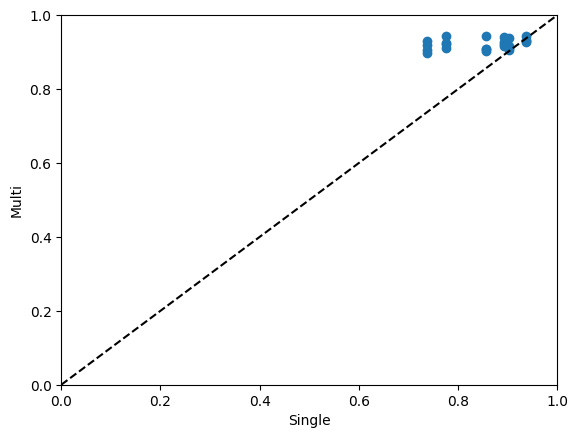

In [5]:
single=[]
import matplotlib.pyplot as plt
import os
import pandas as pd
multi=[]
for file in os.listdir("/home/s0shar47/scratch/Recharge_reitz/Basin_wise_csv/"):
    data= pd.read_csv(os.path.join("/home/s0shar47/scratch/Recharge_reitz/Basin_wise_csv/",file))

    single.append(data['tiff'].corr(data['sim_old']))

    multi.append(data['tiff'].corr(data['sim_new']))

metrics= pd.DataFrame({'Corr_Single':single, 'Corr_Multi':multi})
plt.figure()
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    linewidth=1.5)
plt.scatter(metrics['Corr_Single'],metrics['Corr_Multi'])
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('Single')
plt.ylabel('Multi')
plt.show()

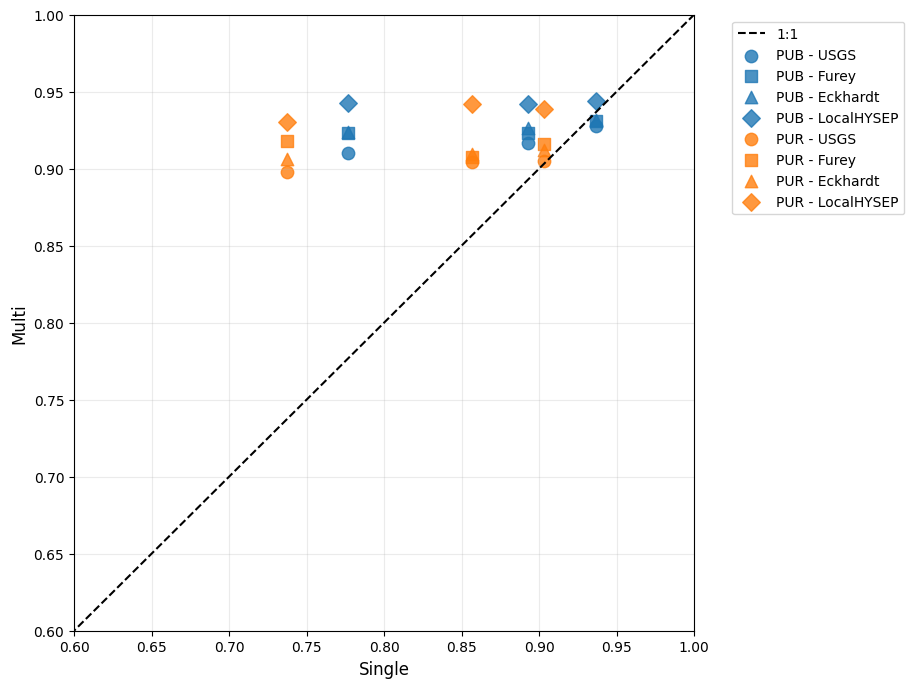

In [9]:
import matplotlib.pyplot as plt
import os
import pandas as pd


# ============================================================
# SETTINGS
# ============================================================

DATA_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Basin_wise_csv/"
)


# ============================================================
# COLORS FOR TEST
# ============================================================

test_colors = {
    "PUB": "tab:blue",
    "PUR": "tab:orange"
}


# ============================================================
# MARKERS FOR METHOD
# ============================================================

method_markers = {
    "USGS": "o",
    "Furey": "s",
    "Eckhardt": "^",
    "LocalHYSEP": "D"
}


# ============================================================
# STORE RESULTS
# ============================================================

results = []


# ============================================================
# LOOP FILES
# ============================================================

for file in os.listdir(DATA_DIR):

    # Only use annual recharge CSVs
    if not file.startswith(
        "annual_recharge_"
    ):
        continue

    if not file.endswith(
        ".csv"
    ):
        continue


    # --------------------------------------------------------
    # Read data
    # --------------------------------------------------------

    path = os.path.join(
        DATA_DIR,
        file
    )

    data = pd.read_csv(
        path
    )


    # --------------------------------------------------------
    # Calculate correlations
    # --------------------------------------------------------

    corr_single = data[
        "tiff"
    ].corr(
        data["sim_old"]
    )

    corr_multi = data[
        "tiff"
    ].corr(
        data["sim_new"]
    )


    # --------------------------------------------------------
    # Parse filename
    #
    # Example:
    #
    # annual_recharge_PUR_Furey_HBV_2000_2013.csv
    #
    #       0        1    2     3      4      5
    # annual_recharge_PUR_Furey_HBV_2000_2013.csv
    #
    # test   = PUR
    # method = Furey
    # model  = HBV
    # --------------------------------------------------------

    name = file.replace(
        ".csv",
        ""
    )

    parts = name.split("_")


    test = parts[2]

    method = parts[3]

    model = parts[4]


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    results.append(
        {
            "file": file,
            "test": test,
            "method": method,
            "model": model,
            "Corr_Single": corr_single,
            "Corr_Multi": corr_multi
        }
    )


# ============================================================
# CREATE DATAFRAME
# ============================================================

metrics = pd.DataFrame(
    results
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(8, 8)
)


# ------------------------------------------------------------
# 1:1 LINE
# ------------------------------------------------------------

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    label="1:1"
)


# ============================================================
# PLOT EACH TEST + METHOD
# ============================================================

for test in [
    "PUB",
    "PUR"
]:

    for method in [
        "USGS",
        "Furey",
        "Eckhardt",
        "LocalHYSEP"
    ]:

        subset = metrics[
            (metrics["test"] == test)
            &
            (metrics["method"] == method)
        ]


        if len(subset) == 0:
            continue


        plt.scatter(
            subset["Corr_Single"],
            subset["Corr_Multi"],

            color=test_colors[test],

            marker=method_markers[method],

            s=80,

            alpha=0.8,

            label=f"{test} - {method}"
        )


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0.6,
    1
)

plt.ylim(
    0.6,
    1
)

plt.xlabel(
    "Single",
    fontsize=12
)

plt.ylabel(
    "Multi",
    fontsize=12
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    alpha=0.25
)


# plt.tight_layout()

plt.show()

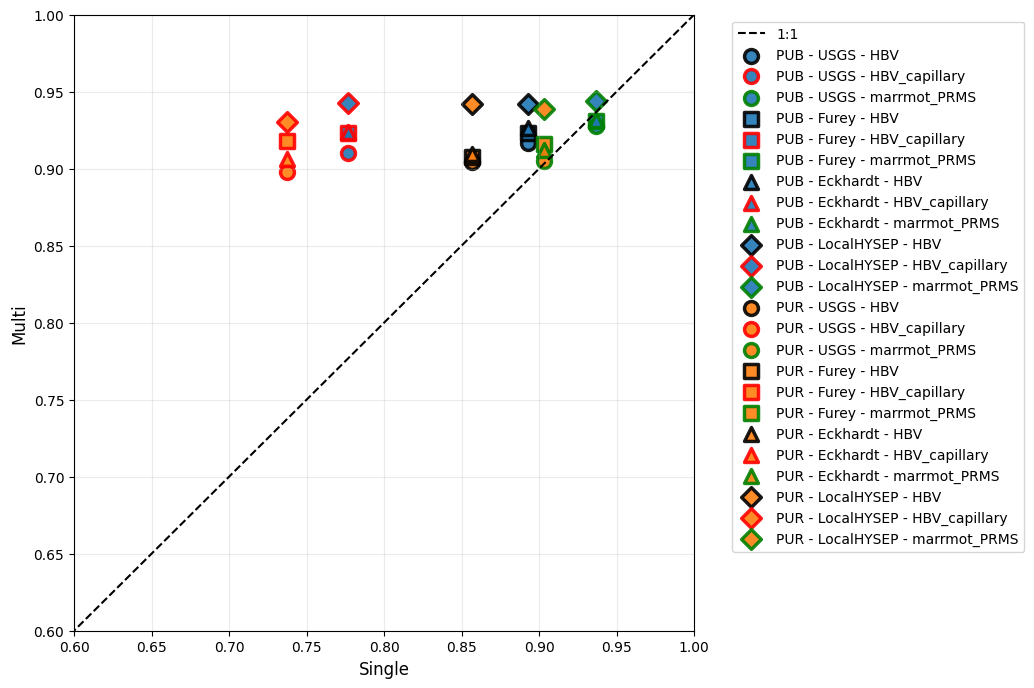

In [10]:
import matplotlib.pyplot as plt
import os
import pandas as pd


# ============================================================
# SETTINGS
# ============================================================

DATA_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Basin_wise_csv/"
)


# ============================================================
# COLORS FOR TEST
# ============================================================

test_colors = {
    "PUB": "tab:blue",
    "PUR": "tab:orange"
}


# ============================================================
# MARKERS FOR METHOD
# ============================================================

method_markers = {
    "USGS": "o",
    "Furey": "s",
    "Eckhardt": "^",
    "LocalHYSEP": "D"
}


# ============================================================
# OUTLINE COLORS FOR MODEL
# ============================================================

model_edgecolors = {
    "HBV": "black",
    "HBV_capillary": "red",
    "marrmot_PRMS": "green"
}


# ============================================================
# STORE RESULTS
# ============================================================

results = []


# ============================================================
# LOOP FILES
# ============================================================

for file in os.listdir(DATA_DIR):

    if not file.startswith(
        "annual_recharge_"
    ):
        continue

    if not file.endswith(
        ".csv"
    ):
        continue


    # --------------------------------------------------------
    # Read data
    # --------------------------------------------------------

    path = os.path.join(
        DATA_DIR,
        file
    )

    data = pd.read_csv(
        path
    )


    # --------------------------------------------------------
    # Calculate correlations
    # --------------------------------------------------------

    corr_single = data[
        "tiff"
    ].corr(
        data["sim_old"]
    )

    corr_multi = data[
        "tiff"
    ].corr(
        data["sim_new"]
    )


    # ========================================================
    # PARSE FILENAME
    # ========================================================

    # Example:
    #
    # annual_recharge_PUR_Furey_HBV_2000_2013.csv
    #
    # annual_recharge_PUB_Eckhardt_HBV_capillary_2000_2013.csv
    # annual_recharge_PUR_Eckhardt_marrmot_PRMS_2000_2013.csv


    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------

    if "_PUB_" in file:

        test = "PUB"

    elif "_PUR_" in file:

        test = "PUR"

    else:

        continue


    # --------------------------------------------------------
    # METHOD
    # --------------------------------------------------------

    method = None

    for m in method_markers:

        if f"_{m}_" in file:

            method = m
            break


    if method is None:

        continue


    # --------------------------------------------------------
    # MODEL
    # --------------------------------------------------------

    if "_HBV_capillary_" in file:

        model = "HBV_capillary"

    elif "_marrmot_PRMS_" in file:

        model = "marrmot_PRMS"

    elif "_HBV_" in file:

        model = "HBV"

    else:

        continue


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    results.append(
        {
            "file": file,
            "test": test,
            "method": method,
            "model": model,
            "Corr_Single": corr_single,
            "Corr_Multi": corr_multi
        }
    )


# ============================================================
# CREATE DATAFRAME
# ============================================================

metrics = pd.DataFrame(
    results
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(8, 8)
)


# ============================================================
# 1:1 LINE
# ============================================================

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    label="1:1"
)


# ============================================================
# PLOT EACH TEST + METHOD + MODEL
# ============================================================

for test in [
    "PUB",
    "PUR"
]:

    for method in [
        "USGS",
        "Furey",
        "Eckhardt",
        "LocalHYSEP"
    ]:

        for model in [
            "HBV",
            "HBV_capillary",
            "marrmot_PRMS"
        ]:


            # ------------------------------------------------
            # Select data
            # ------------------------------------------------

            subset = metrics[
                (metrics["test"] == test)
                &
                (metrics["method"] == method)
                &
                (metrics["model"] == model)
            ]


            if len(subset) == 0:

                continue


            # ------------------------------------------------
            # Scatter
            # ------------------------------------------------

            plt.scatter(

                subset["Corr_Single"],

                subset["Corr_Multi"],

                # Fill = PUB/PUR
                color=test_colors[test],

                # Shape = method
                marker=method_markers[method],

                # Outline = model
                edgecolors=model_edgecolors[model],

                linewidths=2.5,

                s=100,

                alpha=0.9,

                label=(
                    f"{test} - "
                    f"{method} - "
                    f"{model}"
                )
            )


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0.6,
    1
)

plt.ylim(
    0.6,
    1
)


plt.xlabel(
    "Single",
    fontsize=12
)

plt.ylabel(
    "Multi",
    fontsize=12
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    alpha=0.25
)


plt.show()

In [4]:
metrics

,Corr_Single,Corr_Multi
0,0.856701,0.907833
1,0.893016,0.916950
2,0.893016,0.926511
3,0.776630,0.923928
4,0.903039,0.912171
5,0.776630,0.910154
6,0.737489,0.906552
7,0.903039,0.904762
8,0.776630,0.923154
9,0.737489,0.917879
